# 04 — Candidate agents vs fixed external benchmarks

This notebook compares four internal checkpoints and the external `deep_learning_killer` challenger in a fixed four-player line-up against previous-cohort agents. External agents are loaded through evaluation-only symbolic-link adapters; their source and models are not modified.

## Locked protocol

Each match uses `candidate + feature_is_everything + sarsa + q_learning`, classic scenario, fixed seat order, and identical seeds for every candidate. This preliminary comparison uses seeds 63001–63003 and 10 rounds per seed (30 rounds per candidate). Raw results remain under `results/external_benchmark/internal_challenge/`.

In [1]:
from __future__ import annotations

import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown

def find_project_root(start=None):
    candidate = Path(start or Path.cwd()).resolve()
    for directory in (candidate, *candidate.parents):
        if (directory / 'main.py').is_file() and (directory / 'agent_code').is_dir():
            return directory
    raise FileNotFoundError('Could not find the project root containing main.py and agent_code/')

ROOT = find_project_root()
RESULT_DIR = ROOT / 'results' / 'external_benchmark' / 'internal_challenge'
REPORT = RESULT_DIR / 'report.json'
CANDIDATES = ['dueling_ddqn_agent', 'dueling_hunt_center_04', 'frozen_ddqn_day7', 'hunt_center_04_mix_0800', 'external_deep_learning_killer']
INTERNAL = CANDIDATES  # Backward-compatible variable name used by the analysis cells.
EXTERNAL = ['external_feature_is_everything', 'external_sarsa', 'external_q_learning']
SEEDS = [63001, 63002, 63003]
ROUNDS_PER_SEED = 10
assert (ROOT / 'main.py').exists()
print(f'{len(INTERNAL)} candidates × {len(SEEDS)} seeds × {ROUNDS_PER_SEED} rounds')

5 candidates × 3 seeds × 10 rounds


In [2]:
# Reuse finished raw files and run only missing candidates/seeds.
# Set FORCE_RERUN=True only to intentionally replace every locked result.
FORCE_RERUN = False
existing_payload = json.loads(REPORT.read_text(encoding='utf-8')) if REPORT.exists() else None
report_is_complete = (existing_payload is not None and
                      existing_payload.get('seeds') == SEEDS and
                      existing_payload.get('rounds_per_seed') == ROUNDS_PER_SEED and
                      existing_payload.get('internal_agents') == INTERNAL and
                      all(row.get('completed_seeds') == len(SEEDS)
                          for row in existing_payload.get('comparisons', [])))
if FORCE_RERUN or not report_is_complete:
    cmd = [sys.executable, 'evaluation/run_internal_vs_external.py',
           '--rounds', str(ROUNDS_PER_SEED), '--seeds', *map(str, SEEDS)]
    if not FORCE_RERUN:
        cmd.append('--resume')
    subprocess.run(cmd, cwd=ROOT, check=True)
payload = json.loads(REPORT.read_text(encoding='utf-8'))
assert payload['seeds'] == SEEDS
assert payload['rounds_per_seed'] == ROUNDS_PER_SEED
assert payload['internal_agents'] == INTERNAL
assert all(row['completed_seeds'] == len(SEEDS) for row in payload['comparisons'])
print('Loaded:', REPORT.relative_to(ROOT))

Loaded: results/external_benchmark/internal_challenge/report.json


In [3]:
aggregate_rows, seed_rows = [], []
for comparison in payload['comparisons']:
    candidate = comparison['candidate']
    for row in comparison['aggregate_agents']:
        aggregate_rows.append({'internal_lineup': candidate, **row})
    for seed_block in comparison['by_seed']:
        for row in seed_block['agents']:
            seed_rows.append({'internal_lineup': candidate, 'seed': seed_block['seed'], **row})
aggregate = pd.DataFrame(aggregate_rows)
per_seed = pd.DataFrame(seed_rows)
aggregate.to_csv(RESULT_DIR / 'aggregate_agents.csv', index=False)
per_seed.to_csv(RESULT_DIR / 'per_seed_agents.csv', index=False)
cols = ['internal_lineup', 'agent', 'rounds', 'mean_score', 'mean_score_margin', 'win_rate', 'mean_rank',
        'kills_per_round', 'suicides_per_round', 'invalid_per_round',
        'survival_rate', 'mean_action_ms']
display(aggregate[cols].round(3))

,internal_lineup,agent,rounds,mean_score,mean_score_margin,win_rate,mean_rank,kills_per_round,suicides_per_round,invalid_per_round,survival_rate,mean_action_ms
0,dueling_ddqn_agent,dueling_ddqn_agent,30,2.700,-0.189,0.267,2.567,0.200,0.233,3.100,0.667,2.393
1,dueling_ddqn_agent,external_feature_is_everything,30,2.333,-0.678,0.267,2.633,0.067,0.133,4.600,0.800,10.082
2,dueling_ddqn_agent,external_sarsa,30,3.233,0.522,0.367,1.867,0.133,0.100,3.400,0.767,6.666
3,dueling_ddqn_agent,external_q_learning,30,3.100,0.344,0.367,2.067,0.100,0.233,6.333,0.667,6.702
4,dueling_hunt_center_04,dueling_hunt_center_04,30,3.300,0.267,0.367,2.367,0.367,0.167,2.267,0.733,2.357
5,dueling_hunt_center_04,external_feature_is_everything,30,2.867,-0.311,0.333,2.367,0.100,0.100,4.433,0.767,10.103
6,dueling_hunt_center_04,external_sarsa,30,2.833,-0.356,0.200,2.033,0.067,0.167,5.200,0.633,6.749
7,dueling_hunt_center_04,external_q_learning,30,3.400,0.400,0.300,2.133,0.167,0.200,5.400,0.633,6.594
8,frozen_ddqn_day7,frozen_ddqn_day7,30,2.100,-1.011,0.267,2.667,0.067,0.100,8.567,0.667,2.624
9,frozen_ddqn_day7,external_feature_is_everything,30,3.467,0.811,0.367,1.933,0.200,0.067,6.833,0.833,9.651


## Four-player scores and external-average margin

For each internal line-up, the table below shows all four agents' mean scores. `margin_vs_external_mean` is defined as the internal agent's score minus the arithmetic mean score of the three external agents. Positive values mean that our model outscored the external benchmark average. The framework's round-level `mean_score_margin` is checked against the same calculation.

In [4]:
matchup_rows = []
for candidate in INTERNAL:
    block = aggregate[aggregate.internal_lineup.eq(candidate)].set_index('agent')
    internal_score = block.loc[candidate, 'mean_score']
    external_scores = block.loc[EXTERNAL, 'mean_score']
    computed_margin = internal_score - external_scores.mean()
    reported_margin = block.loc[candidate, 'mean_score_margin']
    assert np.isclose(computed_margin, reported_margin)
    matchup_rows.append({
        'internal_agent': candidate,
        'internal_score': internal_score,
        'feature_is_everything_score': external_scores[EXTERNAL[0]],
        'sarsa_score': external_scores[EXTERNAL[1]],
        'q_learning_score': external_scores[EXTERNAL[2]],
        'external_mean_score': external_scores.mean(),
        'margin_vs_external_mean': computed_margin,
        'external_agents_outscored': int((internal_score > external_scores).sum()),
        'score_rank_in_matchup': 1 + int((external_scores > internal_score).sum()),
    })
matchup_scores = pd.DataFrame(matchup_rows).sort_values('margin_vs_external_mean', ascending=False)
matchup_scores.to_csv(RESULT_DIR / 'four_player_score_comparison.csv', index=False)
display(matchup_scores.round(3))

seed_margin_rows = []
for (candidate, seed), block in per_seed.groupby(['internal_lineup', 'seed']):
    scores = block.set_index('agent')['mean_score']
    external_mean = scores.loc[EXTERNAL].mean()
    seed_margin_rows.append({
        'internal_agent': candidate, 'seed': seed,
        'internal_score': scores[candidate],
        'external_mean_score': external_mean,
        'margin_vs_external_mean': scores[candidate] - external_mean,
    })
seed_margins = pd.DataFrame(seed_margin_rows)
margin_summary = seed_margins.groupby('internal_agent')['margin_vs_external_mean'].agg(['mean', 'std', lambda x: (x > 0).mean()])
margin_summary.columns = ['mean_margin', 'seed_margin_sd', 'positive_seed_fraction']
seed_margins.to_csv(RESULT_DIR / 'score_margin_by_seed.csv', index=False)
margin_summary.to_csv(RESULT_DIR / 'score_margin_summary.csv')
display(Markdown('### Margin by seed'))
display(seed_margins.sort_values(['internal_agent', 'seed']).round(3))
display(Markdown('### Margin summary'))
display(margin_summary.sort_values('mean_margin', ascending=False).round(3))

,internal_agent,internal_score,feature_is_everything_score,sarsa_score,q_learning_score,external_mean_score,margin_vs_external_mean,external_agents_outscored,score_rank_in_matchup
4,external_deep_learning_killer,2.533,2.167,2.033,2.333,2.178,0.356,3,1
1,dueling_hunt_center_04,3.300,2.867,2.833,3.400,3.033,0.267,2,2
3,hunt_center_04_mix_0800,2.933,3.100,2.800,2.400,2.767,0.167,2,2
0,dueling_ddqn_agent,2.700,2.333,3.233,3.100,2.889,-0.189,1,3
2,frozen_ddqn_day7,2.100,3.467,2.767,3.100,3.111,-1.011,0,4


### Margin by seed

,internal_agent,seed,internal_score,external_mean_score,margin_vs_external_mean
0,dueling_ddqn_agent,63001,3.5,2.800,0.700
1,dueling_ddqn_agent,63002,2.3,2.667,-0.367
2,dueling_ddqn_agent,63003,2.3,3.200,-0.900
3,dueling_hunt_center_04,63001,3.7,2.767,0.933
4,dueling_hunt_center_04,63002,3.1,2.767,0.333
5,dueling_hunt_center_04,63003,3.1,3.567,-0.467
6,external_deep_learning_killer,63001,2.3,2.367,-0.067
7,external_deep_learning_killer,63002,2.0,2.067,-0.067
8,external_deep_learning_killer,63003,3.3,2.100,1.200
9,frozen_ddqn_day7,63001,1.7,3.200,-1.500


### Margin summary

,mean_margin,seed_margin_sd,positive_seed_fraction
internal_agent,,,
external_deep_learning_killer,0.356,0.731,0.333
dueling_hunt_center_04,0.267,0.702,0.667
hunt_center_04_mix_0800,0.167,0.436,0.333
dueling_ddqn_agent,-0.189,0.815,0.333
frozen_ddqn_day7,-1.011,0.707,0.000


## Internal-model comparison

Because all five candidates face the same fixed benchmark policies on the same seeds and fixed seat order, their seed-level results form paired observations. Score is the primary metric; seed variability, safety, invalid actions, rank, survival, and latency are supporting metrics. `external_deep_learning_killer` occupies the candidate slot and is not added as a fourth opponent, because the environment permits only four agents.

In [5]:
candidate_seed = per_seed[per_seed.agent.eq(per_seed.internal_lineup)].copy()
metrics = ['mean_score', 'win_rate', 'mean_rank', 'kills_per_round',
           'suicides_per_round', 'invalid_per_round', 'survival_rate', 'mean_action_ms']
summary = candidate_seed.groupby('agent')[metrics].agg(['mean', 'std'])
summary.columns = ['_'.join(col) for col in summary.columns]
summary = summary.sort_values('mean_score_mean', ascending=False)
summary.to_csv(RESULT_DIR / 'internal_summary.csv')
display(summary.round(3))
display(candidate_seed[['agent', 'seed', *metrics]].sort_values(['agent', 'seed']).round(3))

,mean_score_mean,mean_score_std,win_rate_mean,win_rate_std,mean_rank_mean,mean_rank_std,kills_per_round_mean,kills_per_round_std,suicides_per_round_mean,suicides_per_round_std,invalid_per_round_mean,invalid_per_round_std,survival_rate_mean,survival_rate_std,mean_action_ms_mean,mean_action_ms_std
agent,,,,,,,,,,,,,,,,
dueling_hunt_center_04,3.300,0.346,0.367,0.058,2.367,0.153,0.367,0.115,0.167,0.058,2.267,0.603,0.733,0.115,2.361,0.070
hunt_center_04_mix_0800,2.933,0.208,0.200,0.100,2.467,0.153,0.200,0.000,0.233,0.153,9.400,0.361,0.567,0.115,2.663,0.065
dueling_ddqn_agent,2.700,0.693,0.267,0.058,2.567,0.115,0.200,0.173,0.233,0.153,3.100,0.854,0.667,0.208,2.399,0.063
external_deep_learning_killer,2.533,0.681,0.233,0.153,2.200,0.529,0.067,0.058,0.100,0.000,1.000,0.346,0.900,0.000,6.873,0.330
frozen_ddqn_day7,2.100,0.458,0.267,0.208,2.667,0.451,0.067,0.058,0.100,0.100,8.567,1.877,0.667,0.115,2.626,0.095


,agent,seed,mean_score,win_rate,mean_rank,kills_per_round,suicides_per_round,invalid_per_round,survival_rate,mean_action_ms
0,dueling_ddqn_agent,63001,3.5,0.2,2.7,0.4,0.1,3.9,0.9,2.332
4,dueling_ddqn_agent,63002,2.3,0.3,2.5,0.1,0.4,2.2,0.6,2.408
8,dueling_ddqn_agent,63003,2.3,0.3,2.5,0.1,0.2,3.2,0.5,2.456
12,dueling_hunt_center_04,63001,3.7,0.4,2.4,0.5,0.2,2.2,0.8,2.383
16,dueling_hunt_center_04,63002,3.1,0.4,2.2,0.3,0.2,2.9,0.8,2.283
20,dueling_hunt_center_04,63003,3.1,0.3,2.5,0.3,0.1,1.7,0.6,2.418
48,external_deep_learning_killer,63001,2.3,0.1,2.8,0.1,0.1,0.8,0.9,6.744
52,external_deep_learning_killer,63002,2.0,0.2,2.0,0.0,0.1,0.8,0.9,7.248
56,external_deep_learning_killer,63003,3.3,0.4,1.8,0.1,0.1,1.4,0.9,6.628
24,frozen_ddqn_day7,63001,1.7,0.1,2.7,0.0,0.1,6.4,0.6,2.733


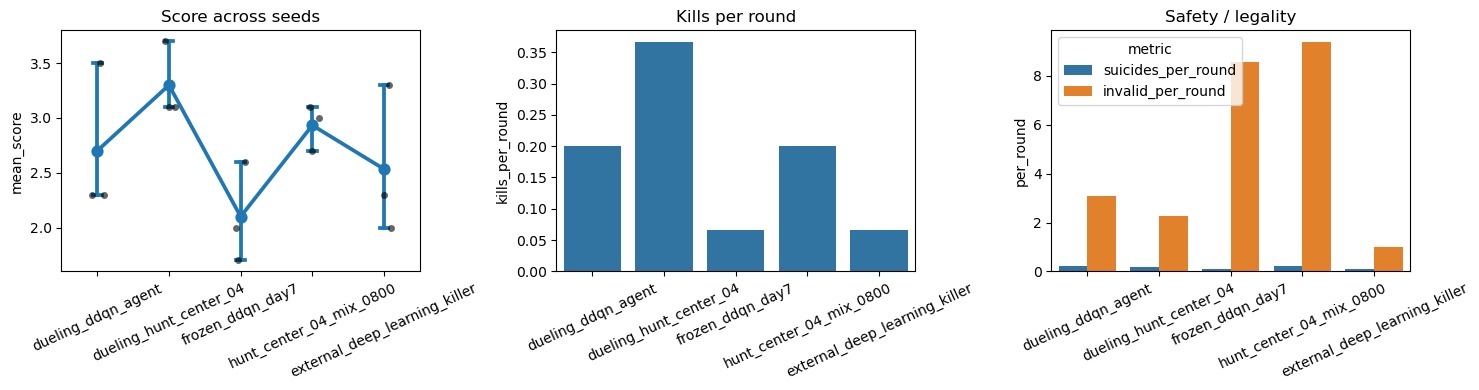

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.pointplot(data=candidate_seed, x='agent', y='mean_score', errorbar=('ci', 95), capsize=.12, ax=axes[0])
sns.stripplot(data=candidate_seed, x='agent', y='mean_score', color='black', alpha=.6, ax=axes[0])
sns.barplot(data=candidate_seed, x='agent', y='kills_per_round', errorbar=None, ax=axes[1])
safety = candidate_seed.melt(id_vars=['agent', 'seed'], value_vars=['suicides_per_round', 'invalid_per_round'], var_name='metric', value_name='per_round')
sns.barplot(data=safety, x='agent', y='per_round', hue='metric', errorbar=None, ax=axes[2])
for ax, title in zip(axes, ['Score across seeds', 'Kills per round', 'Safety / legality']):
    ax.set_title(title); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

In [7]:
winner = summary.index[0]
best = summary.iloc[0]
display(Markdown(
    f'## Preliminary conclusion\n\n'
    f'By the pre-specified primary metric, **{winner}** ranks first with '
    f'`{best.mean_score_mean:.3f}` mean score per round across the three seeds '
    f'(seed-level SD `{best.mean_score_std:.3f}`). This is a 30-round-per-model '
    f'preliminary comparison; expand the same locked design before making a final model-selection claim.'
))

## Preliminary conclusion

By the pre-specified primary metric, **dueling_hunt_center_04** ranks first with `3.300` mean score per round across the three seeds (seed-level SD `0.346`). This is a 30-round-per-model preliminary comparison; expand the same locked design before making a final model-selection claim.

## `deep_learning_killer` comparison

| candidate | mean score | seed SD | win rate | mean rank | margin vs external mean | kills | suicides | invalid | survival | action time |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| `dueling_hunt_center_04` | **3.300** | 0.346 | **0.367** | 2.367 | +0.267 | **0.367** | 0.167 | 2.267 | 0.733 | 2.357 ms |
| `hunt_center_04_mix_0800` | 2.933 | **0.208** | 0.200 | 2.467 | +0.167 | 0.200 | 0.233 | 9.400 | 0.567 | 2.659 ms |
| `dueling_ddqn_agent` | 2.700 | 0.693 | 0.267 | 2.567 | -0.189 | 0.200 | 0.233 | 3.100 | 0.667 | 2.393 ms |
| `external_deep_learning_killer` | 2.533 | 0.681 | 0.233 | **2.200** | **+0.356** | 0.067 | **0.100** | **1.000** | **0.900** | 6.873 ms |
| `frozen_ddqn_day7` | 2.100 | 0.458 | 0.267 | 2.667 | -1.011 | 0.067 | **0.100** | 8.567 | 0.667 | 2.624 ms |

`external_deep_learning_killer` ranks fourth of the five candidates by the primary metric, with 2.533 score per round. It is safer and more conservative than the DDQN candidates: it has the highest survival rate (0.90), only 0.10 suicides and 1.00 invalid action per round, and the best mean rank (2.20). Its positive +0.356 margin shows that it outscored the average of the three fixed external opponents in its own matches. However, it produces only 0.067 kills per round, has a lower win rate than the original hunt-center model, and its score varies substantially across seeds (SD 0.681). Its 6.873 ms action time is slower than the internal DDQN models but remains far below the 500 ms limit.

The new comparison does not change the model-selection result. `dueling_hunt_center_04` remains first by mean score, win rate, and kills, while also keeping invalid actions low. These estimates use only 30 rounds per candidate, so the ranking remains preliminary.